# Gaussian Filter

In [1]:
import numpy as np
from skimage import io, img_as_float
import matplotlib.pyplot as plt

def gaussian_kernel(size, sigma=0):
    """
    Generate a 2D Gaussian kernel.

    Args:
        size (int): Size of the kernel (must be odd).
        sigma (float): Standard deviation for the Gaussian distribution. 

    Returns:
        numpy.ndarray: A 2D Gaussian kernel normalized to sum to 1.
    """
    if sigma == 0:
        # Default sigma calculation based on OpenCV's heuristic
        sigma = 0.3 * ((size - 1) * 0.5 - 1) + 0.8

    # Generate 1D Gaussian kernel
    kernel_1d = np.exp(-np.arange(-(size // 2), size // 2 + 1)**2 / (2 * sigma**2))
    
    # Create a 2D kernel by taking the outer product
    kernel_2d = np.outer(kernel_1d, kernel_1d)
    
    # Normalize the kernel to ensure the sum is 1
    return kernel_2d / kernel_2d.sum()

def gaussian_filter(image, kernel_size=15, sigma=0):
    """
    Apply a Gaussian filter to an image.

    Args:
        image (numpy.ndarray): Input image (grayscale or RGB).
        kernel_size (int): Size of the Gaussian kernel.
        sigma (float): Standard deviation for the Gaussian kernel. 

    Returns:
        numpy.ndarray: Filtered image with the same dimensions as the input.
    """
    # Determine image dimensions and channels
    if len(image.shape) == 3:
        height, width, channels = image.shape
    else:
        height, width = image.shape
        channels = 1
        image = image.reshape((height, width, 1))
    
    # Calculate padding size
    pad_size = kernel_size // 2
    filtered = np.zeros_like(image, dtype=np.float32)
    
    # Generate the Gaussian kernel
    kernel = gaussian_kernel(kernel_size, sigma)
    
    # Pad the image to handle edge pixels
    padded = np.pad(image, ((pad_size, pad_size), (pad_size, pad_size), (0, 0)), mode='reflect')
    
    # Apply the filter to each channel independently
    for c in range(channels):
        for i in range(height):
            for j in range(width):
                # Extract the local window for the current pixel
                window = padded[i:i+kernel_size, j:j+kernel_size, c]
                
                # Compute the filtered pixel value using the Gaussian kernel
                filtered[i, j, c] = np.sum(window * kernel)
    
    # Clip values to valid range [0, 255] and cast to integer
    return np.clip(filtered, 0, 255).astype(np.uint8)


# Bilateral Filter

In [2]:
def bilateral_filter(image, kernel_size=15, sigma_color=75, sigma_space=75):
    """
    Apply a bilateral filter to an image.

    Args:
        image (numpy.ndarray): Input image (grayscale or RGB).
        kernel_size (int): Size of the kernel.
        sigma_color (float): Standard deviation for color intensity differences.
        sigma_space (float): Standard deviation for spatial distance.

    Returns:
        numpy.ndarray: Filtered image with the same dimensions as the input.
    """
    # Determine image dimensions and channels
    if len(image.shape) == 3:
        height, width, channels = image.shape
    else:
        height, width = image.shape
        channels = 1
        image = image.reshape((height, width, 1))

    # Calculate padding size
    pad_size = kernel_size // 2
    filtered = np.zeros_like(image, dtype=np.float32)

    # Generate spatial weight kernel (Gaussian weights based on spatial distance)
    space_kernel = gaussian_kernel(kernel_size, sigma_space)

    # Pad the image to handle edge pixels
    padded = np.pad(image, ((pad_size, pad_size), (pad_size, pad_size), (0, 0)), mode='reflect')

    # Apply the filter to each channel independently
    for c in range(channels):
        for i in range(height):
            for j in range(width):
                # Extract the local window for the current pixel
                window = padded[i:i+kernel_size, j:j+kernel_size, c].astype(np.float32)
                
                # Value of the center pixel
                center_value = image[i, j, c]
                
                # Compute color weights based on intensity differences
                color_weights = np.exp(-((window - center_value) ** 2) / (2 * sigma_color ** 2))
                
                # Combine spatial and color weights
                weights = space_kernel * color_weights
                
                # Normalize the weights
                weights = weights / np.sum(weights)
                
                # Compute the filtered pixel value
                filtered[i, j, c] = np.sum(window * weights)

    # Clip values to valid range [0, 255] and cast to integer
    return np.clip(filtered, 0, 255).astype(np.uint8)


# Non Local Means Filter

In [3]:
def find_all_neighbors(padded_image, patch_size):
    """
    Precompute neighborhoods (patches) for all pixels in the padded image.

    Args:
        padded_image (numpy.ndarray): Padded input image.
        patch_size (int): Size of the patch for comparison.

    Returns:
        numpy.ndarray: A 4D array where each pixel has a corresponding patch of size (patch_size x patch_size).
    """
    height, width = padded_image.shape
    patch_radius = patch_size // 2
    neighbors = np.zeros((height, width, patch_size, patch_size))

    # Iterate over each pixel, excluding borders based on patch size
    for y in range(patch_radius, height - patch_radius):
        for x in range(patch_radius, width - patch_radius):
            # Extract a patch centered at the current pixel
            neighbors[y, x] = padded_image[y-patch_radius:y+patch_radius+1, 
                                           x-patch_radius:x+patch_radius+1]
    return neighbors

def compute_weight(reference_patch, neighbor_patch, strength):
    """
    Compute the weight between two patches based on similarity.

    Args:
        reference_patch (numpy.ndarray): Reference patch.
        neighbor_patch (numpy.ndarray): Neighboring patch.
        strength (float): Filtering strength; controls decay of weights based on differences.

    Returns:
        float: Weight indicating similarity between the two patches.
    """
    # Compute squared Euclidean distance between patches
    distance = np.sum((reference_patch - neighbor_patch) ** 2)
    
    # Exponential decay to calculate weight
    return np.exp(-distance / (strength * strength))

def non_local_means_filter(image, strength=10, patch_size=7, search_window_size=21):
    """
    Apply Non-Local Means filter to an image.

    Args:
        image (numpy.ndarray): Input image (grayscale or RGB).
        strength (float): Filtering strength; larger values result in stronger smoothing.
        patch_size (int): Size of the patch used for similarity comparison.
        search_window_size (int): Size of the search area for finding similar patches.

    Returns:
        numpy.ndarray: Filtered image with the same dimensions as the input.
    """
    # Check if the input is RGB or grayscale
    if len(image.shape) == 3:  # RGB image
        filtered_image = np.zeros_like(image)
        for channel in range(image.shape[2]):
            print(f"Processing channel {channel + 1}/{image.shape[2]}")
            # Process each channel independently using recursion
            filtered_image[:, :, channel] = non_local_means_filter(
                image[:, :, channel], strength, patch_size, search_window_size
            )
        return filtered_image

    # For grayscale images
    height, width = image.shape

    # Calculate padding sizes
    patch_radius = patch_size // 2  # Radius of the patch
    search_radius = search_window_size // 2  # Radius of the search area
    padding_size = search_radius + patch_radius  # Total padding size

    # Pad the input image to handle edges
    padded_image = np.pad(image, padding_size, mode='reflect')

    # Initialize the result image
    filtered_image = np.zeros_like(image, dtype=np.float32)

    # Precompute patches for all pixels in the padded image
    print("Computing neighborhoods...")
    neighbors = find_all_neighbors(padded_image, patch_size)

    print("Applying Non-local means filter...")
    # Iterate over each pixel in the original image
    for y in range(height):
        if y % 100 == 0:  # Print progress every 100 rows
            print(f"Processing row {y}/{height}")
        for x in range(width):
            # Determine the center pixel's coordinates in the padded image
            center_y = y + padding_size
            center_x = x + padding_size

            weight_sum = 0  # Sum of weights
            pixel_value_sum = 0  # Weighted pixel value sum

            # Get the reference patch for the current pixel
            reference_patch = neighbors[center_y, center_x]

            # Search for similar patches within the search window
            for dy in range(-search_radius, search_radius + 1):
                for dx in range(-search_radius, search_radius + 1):
                    # Neighbor pixel coordinates in the padded image
                    neighbor_y = center_y + dy
                    neighbor_x = center_x + dx

                    # Check if the neighbor patch is within bounds
                    if (neighbor_y - patch_radius >= 0 and neighbor_y + patch_radius + 1 <= padded_image.shape[0] and
                        neighbor_x - patch_radius >= 0 and neighbor_x + patch_radius + 1 <= padded_image.shape[1]):
                        
                        # Get the neighboring patch
                        neighbor_patch = neighbors[neighbor_y, neighbor_x]

                        # Compute weight between the reference patch and the neighboring patch
                        weight = compute_weight(reference_patch, neighbor_patch, strength)

                        # Accumulate weighted pixel values and weights
                        weight_sum += weight
                        pixel_value_sum += weight * padded_image[neighbor_y, neighbor_x]

            # Compute the final pixel value by normalizing the weighted sum
            if weight_sum > 0:
                filtered_image[y, x] = pixel_value_sum / weight_sum
            else:
                filtered_image[y, x] = image[y, x]  # Fallback to the original value if no weights

    # Clip the result to valid pixel range [0, 255] and convert to integer
    return np.clip(filtered_image, 0, 255).astype(np.uint8)


# Visualization

Applying Gaussian filter...
Applying Bilateral filter...
Applying Non-local means filter...
Processing channel 1/3
Computing neighborhoods...
Applying Non-local means filter...
Processing row 0/220
Processing row 100/220
Processing row 200/220
Processing channel 2/3
Computing neighborhoods...
Applying Non-local means filter...
Processing row 0/220
Processing row 100/220
Processing row 200/220
Processing channel 3/3
Computing neighborhoods...
Applying Non-local means filter...
Processing row 0/220
Processing row 100/220
Processing row 200/220


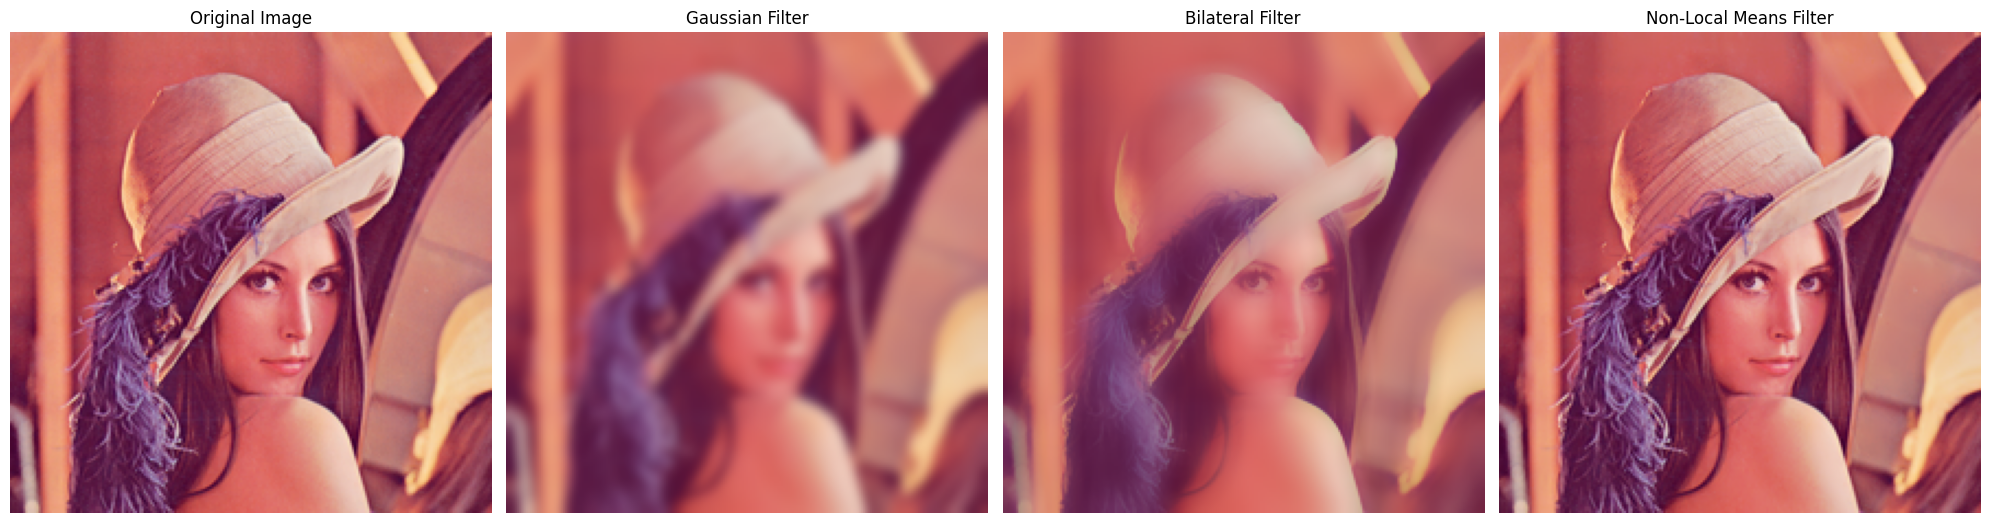

In [4]:
# Read image
image = io.imread('lenna.png')  # Load the input image (grayscale or RGB)

# Apply filters
print("Applying Gaussian filter...")
gaussian_filtered = gaussian_filter(image, kernel_size=15, sigma=0)  
# Gaussian filter with a kernel size of 15x15 and default sigma

print("Applying Bilateral filter...")
bilateral_filtered = bilateral_filter(image, kernel_size=15, sigma_color=75, sigma_space=75)  
# Bilateral filter with a kernel size of 15x15, color sigma=75, and space sigma=75

print("Applying Non-local means filter...")
non_local_means_filtered = non_local_means_filter(image, 
                                strength=10,         # Filtering strength for smoothing
                                patch_size=7,        # Patch size for comparison
                                search_window_size=21)  # Search window size for finding similar patches

# Visualize results
fig, axs = plt.subplots(1, 4, figsize=(20, 10))  # Create a figure with 1 row and 4 columns of subplots

# Display the original image
axs[0].imshow(image)  
axs[0].set_title('Original Image')  # Set the title for the original image
axs[0].axis('off')  # Remove axes for cleaner visualization

# Display the Gaussian filtered image
axs[1].imshow(gaussian_filtered)  
axs[1].set_title('Gaussian Filter')  # Set the title for Gaussian filter
axs[1].axis('off')  # Remove axes for cleaner visualization

# Display the Bilateral filtered image
axs[2].imshow(bilateral_filtered)  
axs[2].set_title('Bilateral Filter')  # Set the title for Bilateral filter
axs[2].axis('off')  # Remove axes for cleaner visualization

# Display the Non-local Means filtered image
axs[3].imshow(non_local_means_filtered)  
axs[3].set_title('Non-Local Means Filter')  # Set the title for Non-local Means filter
axs[3].axis('off')  # Remove axes for cleaner visualization

# Adjust layout to ensure proper spacing between subplots
plt.tight_layout()  
plt.show()  # Display


# Experiments

In [5]:
# Functions to calculate PSNR and MSE
def calculate_psnr(original, filtered):
    """
    Calculate Peak Signal-to-Noise Ratio (PSNR) between the original and filtered images.
    
    Args:
        original (numpy.ndarray): Original image with values in [0, 1].
        filtered (numpy.ndarray): Filtered image with values in [0, 1].
    
    Returns:
        float: PSNR value.
    """
    mse = np.mean((original - filtered) ** 2)
    if mse == 0:
        return float('inf')  # Infinite PSNR if MSE is 0 (perfect match)
    return 20 * np.log10(1.0 / np.sqrt(mse))  # Calculate PSNR

def calculate_mse(original, filtered):
    """
    Calculate Mean Squared Error (MSE) between the original and filtered images.
    
    Args:
        original (numpy.ndarray): Original image with values in [0, 1].
        filtered (numpy.ndarray): Filtered image with values in [0, 1].
    
    Returns:
        float: MSE value.
    """
    return np.mean((original - filtered) ** 2)


# salt and pepper noise

Applying Gaussian filter...
Applying Bilateral filter...
Applying Non-local means filter...
Processing channel 1/3
Computing neighborhoods...
Applying Non-local means filter...
Processing row 0/220
Processing row 100/220
Processing row 200/220
Processing channel 2/3
Computing neighborhoods...
Applying Non-local means filter...
Processing row 0/220
Processing row 100/220
Processing row 200/220
Processing channel 3/3
Computing neighborhoods...
Applying Non-local means filter...
Processing row 0/220
Processing row 100/220
Processing row 200/220


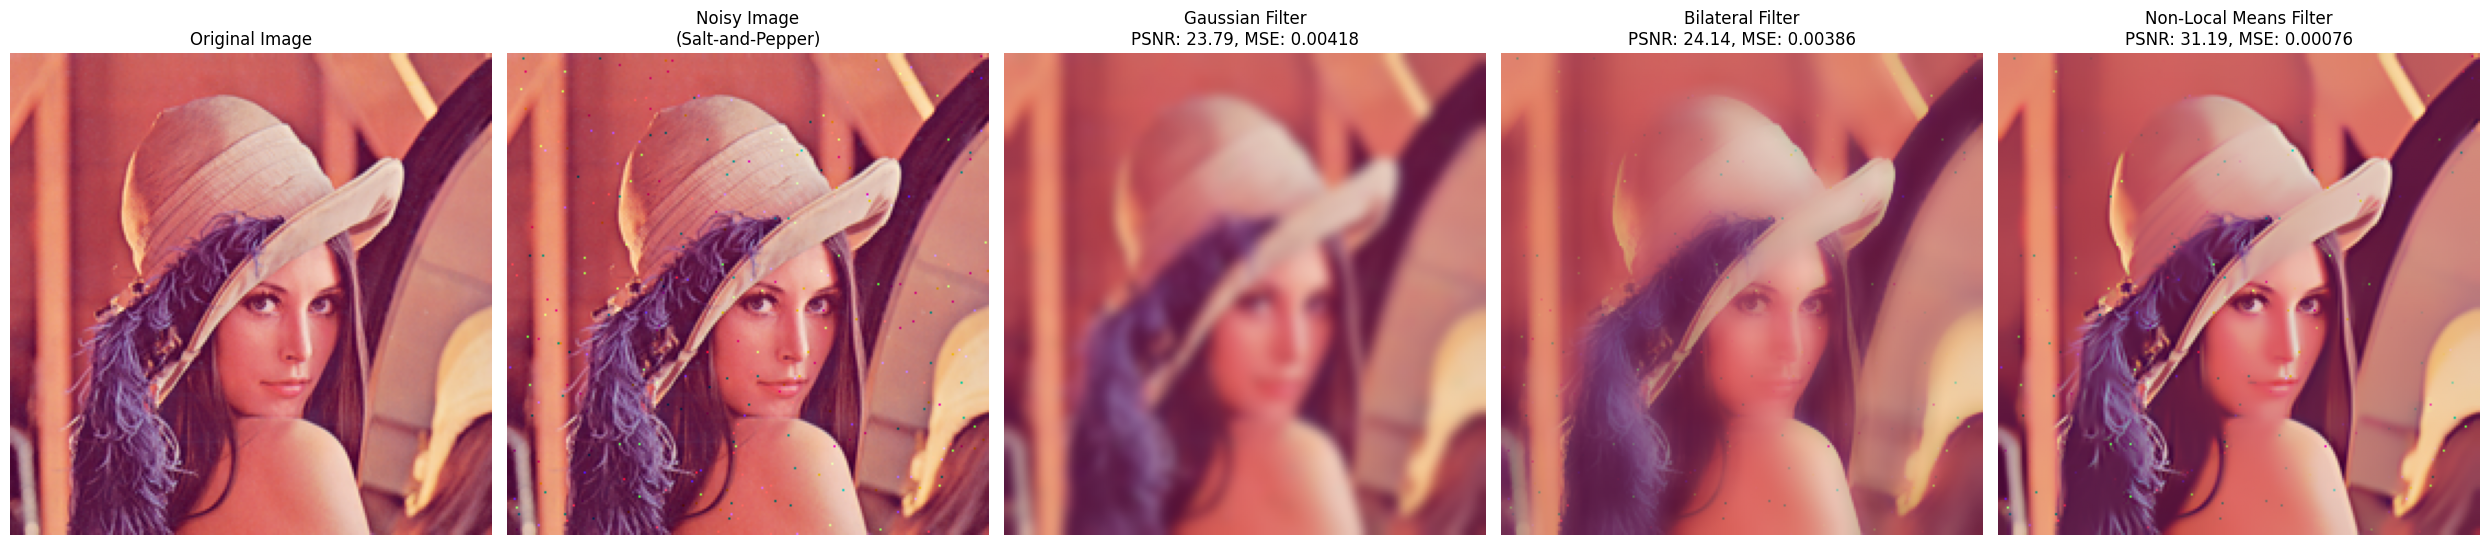

In [6]:
# Add Salt-and-Pepper Noise
def add_salt_and_pepper_noise(image, salt_prob=0.01, pepper_prob=0.01):
    """
    Add salt-and-pepper noise to an image.
    
    Args:
        image (numpy.ndarray): Input image (grayscale or RGB) with values in [0, 1].
        salt_prob (float): Probability of adding salt noise (white pixels).
        pepper_prob (float): Probability of adding pepper noise (black pixels).
    
    Returns:
        numpy.ndarray: Noisy image with salt-and-pepper noise.
    """
    noisy_image = image.copy()
    total_pixels = image.size

    # Add salt noise (white pixels)
    num_salt = int(total_pixels * salt_prob)
    coords_salt = [np.random.randint(0, i, num_salt) for i in image.shape]
    noisy_image[tuple(coords_salt)] = 1.0  # Set salt pixels to maximum (1.0 for normalized images)

    # Add pepper noise (black pixels)
    num_pepper = int(total_pixels * pepper_prob)
    coords_pepper = [np.random.randint(0, i, num_pepper) for i in image.shape]
    noisy_image[tuple(coords_pepper)] = 0.0  # Set pepper pixels to minimum (0.0)

    return noisy_image

# Read and normalize the image to [0, 1]
image = img_as_float(io.imread('lenna.png'))  # Normalize the image to [0, 1]

# Add Salt-and-Pepper Noise
salt_pepper_noisy_image = add_salt_and_pepper_noise(image, salt_prob=0.001, pepper_prob=0.001)

# Apply Gaussian Filter
print("Applying Gaussian filter...")
gaussian_filtered = gaussian_filter((salt_pepper_noisy_image * 255).astype(np.uint8), kernel_size=15, sigma=0) / 255.0

# Apply Bilateral Filter
print("Applying Bilateral filter...")
bilateral_filtered = bilateral_filter((salt_pepper_noisy_image * 255).astype(np.uint8), kernel_size=15, sigma_color=75, sigma_space=75) / 255.0

# Apply Non-Local Means Filter
print("Applying Non-local means filter...")
non_local_means_filtered = non_local_means_filter((salt_pepper_noisy_image * 255).astype(np.uint8), 
                                strength=100, 
                                patch_size=7, 
                                search_window_size=21) / 255.0

# Calculate PSNR and MSE metrics for each filter
metrics = {
    "Gaussian Filter": {
        "PSNR": calculate_psnr(image, gaussian_filtered),
        "MSE": calculate_mse(image, gaussian_filtered)
    },
    "Bilateral Filter": {
        "PSNR": calculate_psnr(image, bilateral_filtered),
        "MSE": calculate_mse(image, bilateral_filtered)
    },
    "Non-Local Means Filter": {
        "PSNR": calculate_psnr(image, non_local_means_filtered),
        "MSE": calculate_mse(image, non_local_means_filtered)
    }
}

# Visualization of results
fig, axs = plt.subplots(1, 5, figsize=(25, 10))

# Display the original image
axs[0].imshow(image, cmap='gray')
axs[0].set_title('Original Image')
axs[0].axis('off')

# Display the noisy image with salt-and-pepper noise
axs[1].imshow(salt_pepper_noisy_image, cmap='gray')
axs[1].set_title('Noisy Image\n(Salt-and-Pepper)')
axs[1].axis('off')

# Display the result of Gaussian Filter
axs[2].imshow(gaussian_filtered, cmap='gray')
axs[2].set_title(f"Gaussian Filter\nPSNR: {metrics['Gaussian Filter']['PSNR']:.2f}, "
                 f"MSE: {metrics['Gaussian Filter']['MSE']:.5f}")
axs[2].axis('off')

# Display the result of Bilateral Filter
axs[3].imshow(bilateral_filtered, cmap='gray')
axs[3].set_title(f"Bilateral Filter\nPSNR: {metrics['Bilateral Filter']['PSNR']:.2f}, "
                 f"MSE: {metrics['Bilateral Filter']['MSE']:.5f}")
axs[3].axis('off')

# Display the result of Non-Local Means Filter
axs[4].imshow(non_local_means_filtered, cmap='gray')
axs[4].set_title(f"Non-Local Means Filter\nPSNR: {metrics['Non-Local Means Filter']['PSNR']:.2f}, "
                 f"MSE: {metrics['Non-Local Means Filter']['MSE']:.5f}")
axs[4].axis('off')

plt.tight_layout()
plt.show()


# Gaussian Noise

Applying Gaussian filter...
Applying Bilateral filter...
Applying Non-local means filter...
Processing channel 1/3
Computing neighborhoods...
Applying Non-local means filter...
Processing row 0/220
Processing row 100/220
Processing row 200/220
Processing channel 2/3
Computing neighborhoods...
Applying Non-local means filter...
Processing row 0/220
Processing row 100/220
Processing row 200/220
Processing channel 3/3
Computing neighborhoods...
Applying Non-local means filter...
Processing row 0/220
Processing row 100/220
Processing row 200/220


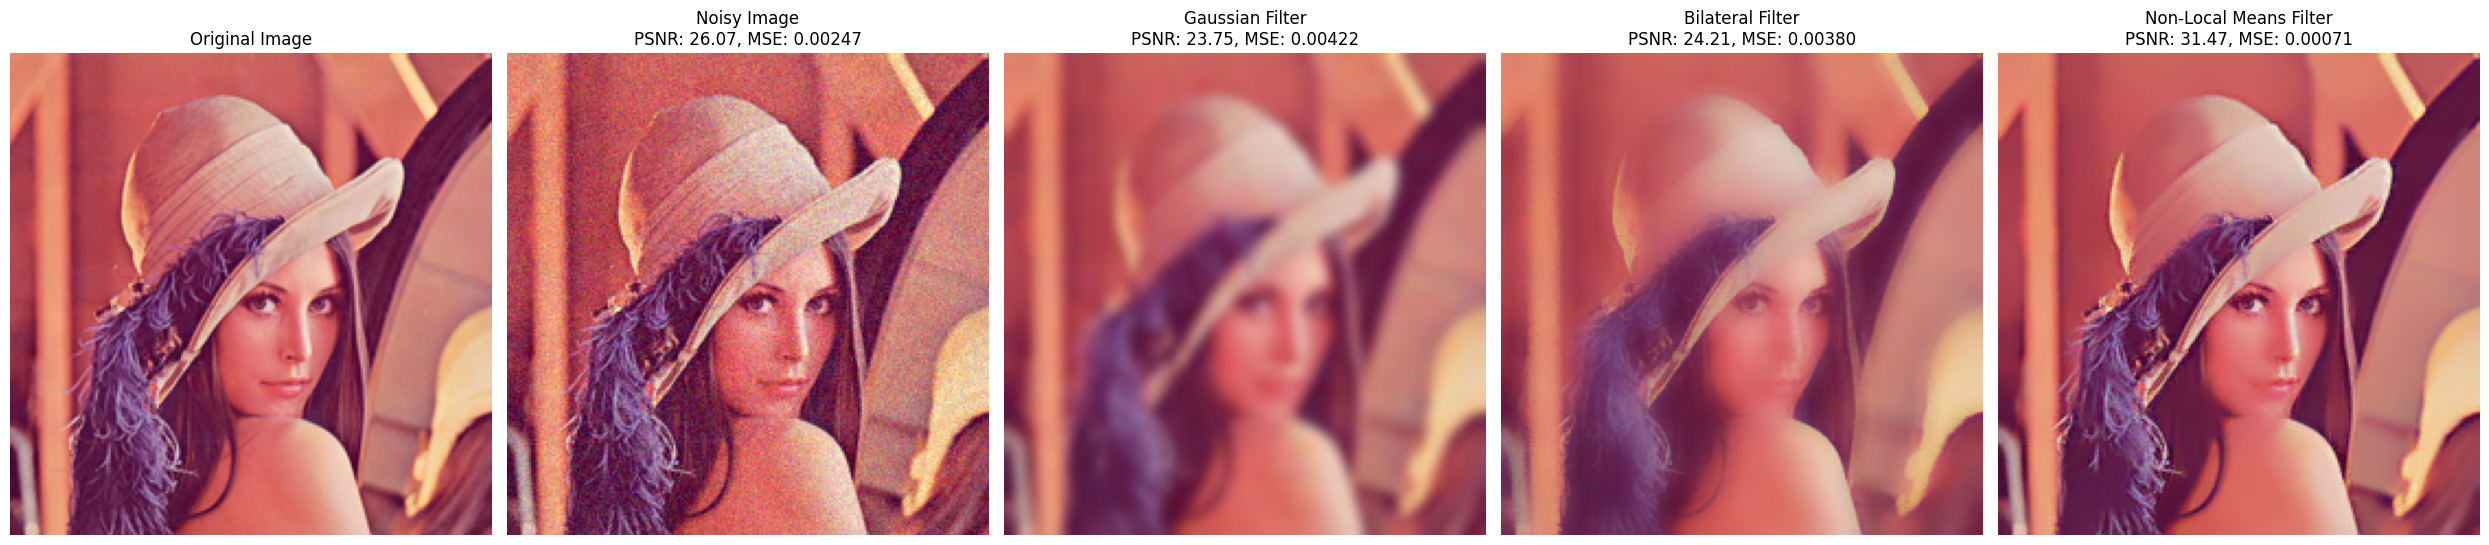

In [7]:
# Add Gaussian noise to the image
def add_gaussian_noise(image, mean=0, std=0.1):
    """
    Add Gaussian noise to an image.

    Args:
        image (numpy.ndarray): Input image (grayscale or RGB) with values in [0, 1].
        mean (float): Mean of the Gaussian noise.
        std (float): Standard deviation of the Gaussian noise.
    
    Returns:
        numpy.ndarray: Image with added Gaussian noise, clipped to [0, 1].
    """
    noise = np.random.normal(mean, std, image.shape)  # Generate Gaussian noise
    noisy_image = image + noise  # Add noise to the image
    return np.clip(noisy_image, 0, 1)  # Ensure pixel values remain within [0, 1]

# PSNR and MSE calculation functions
def calculate_psnr(original, filtered):
    """
    Calculate Peak Signal-to-Noise Ratio (PSNR) between the original and filtered images.

    Args:
        original (numpy.ndarray): Original image with values in [0, 1].
        filtered (numpy.ndarray): Filtered image with values in [0, 1].

    Returns:
        float: PSNR value. Higher PSNR indicates better similarity to the original.
    """
    mse = np.mean((original - filtered) ** 2)  # Calculate Mean Squared Error
    if mse == 0:
        return float('inf')  # Infinite PSNR if MSE is zero
    return 20 * np.log10(1.0 / np.sqrt(mse))  # Compute PSNR using the formula

def calculate_mse(original, filtered):
    """
    Calculate Mean Squared Error (MSE) between the original and filtered images.

    Args:
        original (numpy.ndarray): Original image with values in [0, 1].
        filtered (numpy.ndarray): Filtered image with values in [0, 1].

    Returns:
        float: MSE value. Lower MSE indicates better similarity to the original.
    """
    return np.mean((original - filtered) ** 2)

# Load and normalize the image to [0, 1]
image = img_as_float(io.imread('lenna.png'))  # Normalize pixel values to [0, 1]

# Add Gaussian noise to the image
noisy_image = add_gaussian_noise(image, mean=0, std=0.05)  # Add Gaussian noise with mean=0, std=0.05

# Apply filters to remove noise
print("Applying Gaussian filter...")
gaussian_filtered = gaussian_filter((noisy_image * 255).astype(np.uint8), kernel_size=15, sigma=0) / 255.0  # Apply Gaussian filter

print("Applying Bilateral filter...")
bilateral_filtered = bilateral_filter((noisy_image * 255).astype(np.uint8), kernel_size=15, sigma_color=75, sigma_space=75) / 255.0  # Apply Bilateral filter

print("Applying Non-local means filter...")
non_local_means_filtered = non_local_means_filter((noisy_image * 255).astype(np.uint8), 
                                strength=100, 
                                patch_size=7, 
                                search_window_size=21) / 255.0  # Apply Non-local Means filter

# Calculate PSNR and MSE for each filter
metrics = {
    "Noisy Image": {
        "PSNR": calculate_psnr(image, noisy_image),  # PSNR for noisy image
        "MSE": calculate_mse(image, noisy_image)    # MSE for noisy image
    },
    "Gaussian Filter": {
        "PSNR": calculate_psnr(image, gaussian_filtered),  # PSNR for Gaussian filter
        "MSE": calculate_mse(image, gaussian_filtered)     # MSE for Gaussian filter
    },
    "Bilateral Filter": {
        "PSNR": calculate_psnr(image, bilateral_filtered),  # PSNR for Bilateral filter
        "MSE": calculate_mse(image, bilateral_filtered)     # MSE for Bilateral filter
    },
    "Non-Local Means Filter": {
        "PSNR": calculate_psnr(image, non_local_means_filtered),  # PSNR for Non-local Means filter
        "MSE": calculate_mse(image, non_local_means_filtered)     # MSE for Non-local Means filter
    }
}

# Visualize the results
fig, axs = plt.subplots(1, 5, figsize=(25, 10))

# Display the original image
axs[0].imshow(image, cmap='gray')
axs[0].set_title('Original Image')  # Title for the original image
axs[0].axis('off')  # Hide axis

# Display the noisy image with PSNR and MSE
axs[1].imshow(noisy_image, cmap='gray')
axs[1].set_title(f"Noisy Image\nPSNR: {metrics['Noisy Image']['PSNR']:.2f}, "
                 f"MSE: {metrics['Noisy Image']['MSE']:.5f}")
axs[1].axis('off')

# Display the result of Gaussian filter with PSNR and MSE
axs[2].imshow(gaussian_filtered, cmap='gray')
axs[2].set_title(f"Gaussian Filter\nPSNR: {metrics['Gaussian Filter']['PSNR']:.2f}, "
                 f"MSE: {metrics['Gaussian Filter']['MSE']:.5f}")
axs[2].axis('off')

# Display the result of Bilateral filter with PSNR and MSE
axs[3].imshow(bilateral_filtered, cmap='gray')
axs[3].set_title(f"Bilateral Filter\nPSNR: {metrics['Bilateral Filter']['PSNR']:.2f}, "
                 f"MSE: {metrics['Bilateral Filter']['MSE']:.5f}")
axs[3].axis('off')

# Display the result of Non-local Means filter with PSNR and MSE
axs[4].imshow(non_local_means_filtered, cmap='gray')
axs[4].set_title(f"Non-Local Means Filter\nPSNR: {metrics['Non-Local Means Filter']['PSNR']:.2f}, "
                 f"MSE: {metrics['Non-Local Means Filter']['MSE']:.5f}")
axs[4].axis('off')

plt.tight_layout()  # Adjust layout for better visualization
plt.show()
